# Mini Project: Evaluating Clustering Before and After PCA
In this project we apply K-Means on the Wine dataset before and after PCA, and compare the results.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

### 1. Loading, Splitting, and Scaling the Wine Dataset
In this section, we will load the Wine dataset and verify its integrity by checking for any missing values. Following that, we will split the dataset into training and testing sets to prevent any data leakage. Finally, we will apply feature scaling using standardization (scaling features to have a mean of 0 and a standard deviation of 1).

In [2]:
# Load the Wine dataset from sklearn
data = load_wine()

# Extract the feature matrix (X) and target labels (y)
X = data.data
y = data.target

In [3]:
# Create a DataFrame to easily check for missing values
df_check = pd.DataFrame(X, columns=data.feature_names)

# Check for missing values in each column
missing_values = df_check.isnull().sum()
print("Missing values per column:")
print(missing_values)

# Check if there are any missing values in the entire dataset
total_missing = df_check.isnull().sum().sum()
print(f"\nTotal missing values: {total_missing}")

Missing values per column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total missing values: 0


In [4]:
# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
# Initialize the standard scaler
scaler = StandardScaler()

# Learn the scaling parameters from training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data using the training parameters to prevent data leakage
X_test_scaled = scaler.transform(X_test)

### 2. K-Means Before PCA
We apply K-Means on the original scaled data (13 features). We use $K=3$ because the dataset has 3 classes of wine.

In [6]:
# Apply K-Means on the original scaled training data (Before PCA)
kmeans_before = KMeans(n_clusters=3, random_state=42)
train_labels_before = kmeans_before.fit_predict(X_train_scaled)

# Evaluate clustering using silhouette score
sil_score_before = silhouette_score(X_train_scaled, train_labels_before)
print(f"Silhouette Score before PCA: {sil_score_before:.4f}")

Silhouette Score before PCA: 0.2748


### 3. Apply PCA
We reduce the 13 features to 2 principal components.

In [7]:
# Initialize PCA to reduce the dataset to 2 principal components
pca = PCA(n_components=2, random_state=42)

# Fit and transform the scaled training data
X_train_pca = pca.fit_transform(X_train_scaled)

# Transform the scaled test data using the fitted PCA
X_test_pca = pca.transform(X_test_scaled)

In [8]:
# Check how much information (variance) PCA kept
print("Variance explained by each component:", pca.explained_variance_ratio_)
print("Total variance kept:", pca.explained_variance_ratio_.sum())

Variance explained by each component: [0.35900066 0.18691934]
Total variance kept: 0.5459200022286599


### 4. K-Means After PCA
We apply K-Means again, but this time on the 2 PCA components.

In [9]:
# Apply K-Means on the 2D PCA components (After PCA)
kmeans_after = KMeans(n_clusters=3, random_state=42)
train_labels_after = kmeans_after.fit_predict(X_train_pca)

# Evaluate clustering using silhouette score on PCA components
sil_score_after = silhouette_score(X_train_pca, train_labels_after)
print(f"Silhouette Score after PCA: {sil_score_after:.4f}")

Silhouette Score after PCA: 0.5482


### 5. Visualization
We plot both results on the PCA components so we can compare them. We also plot the true classes to see which result is closer to reality.

Note: K-Means gives random numbers to the clusters, so the same group can have a different color in each plot.

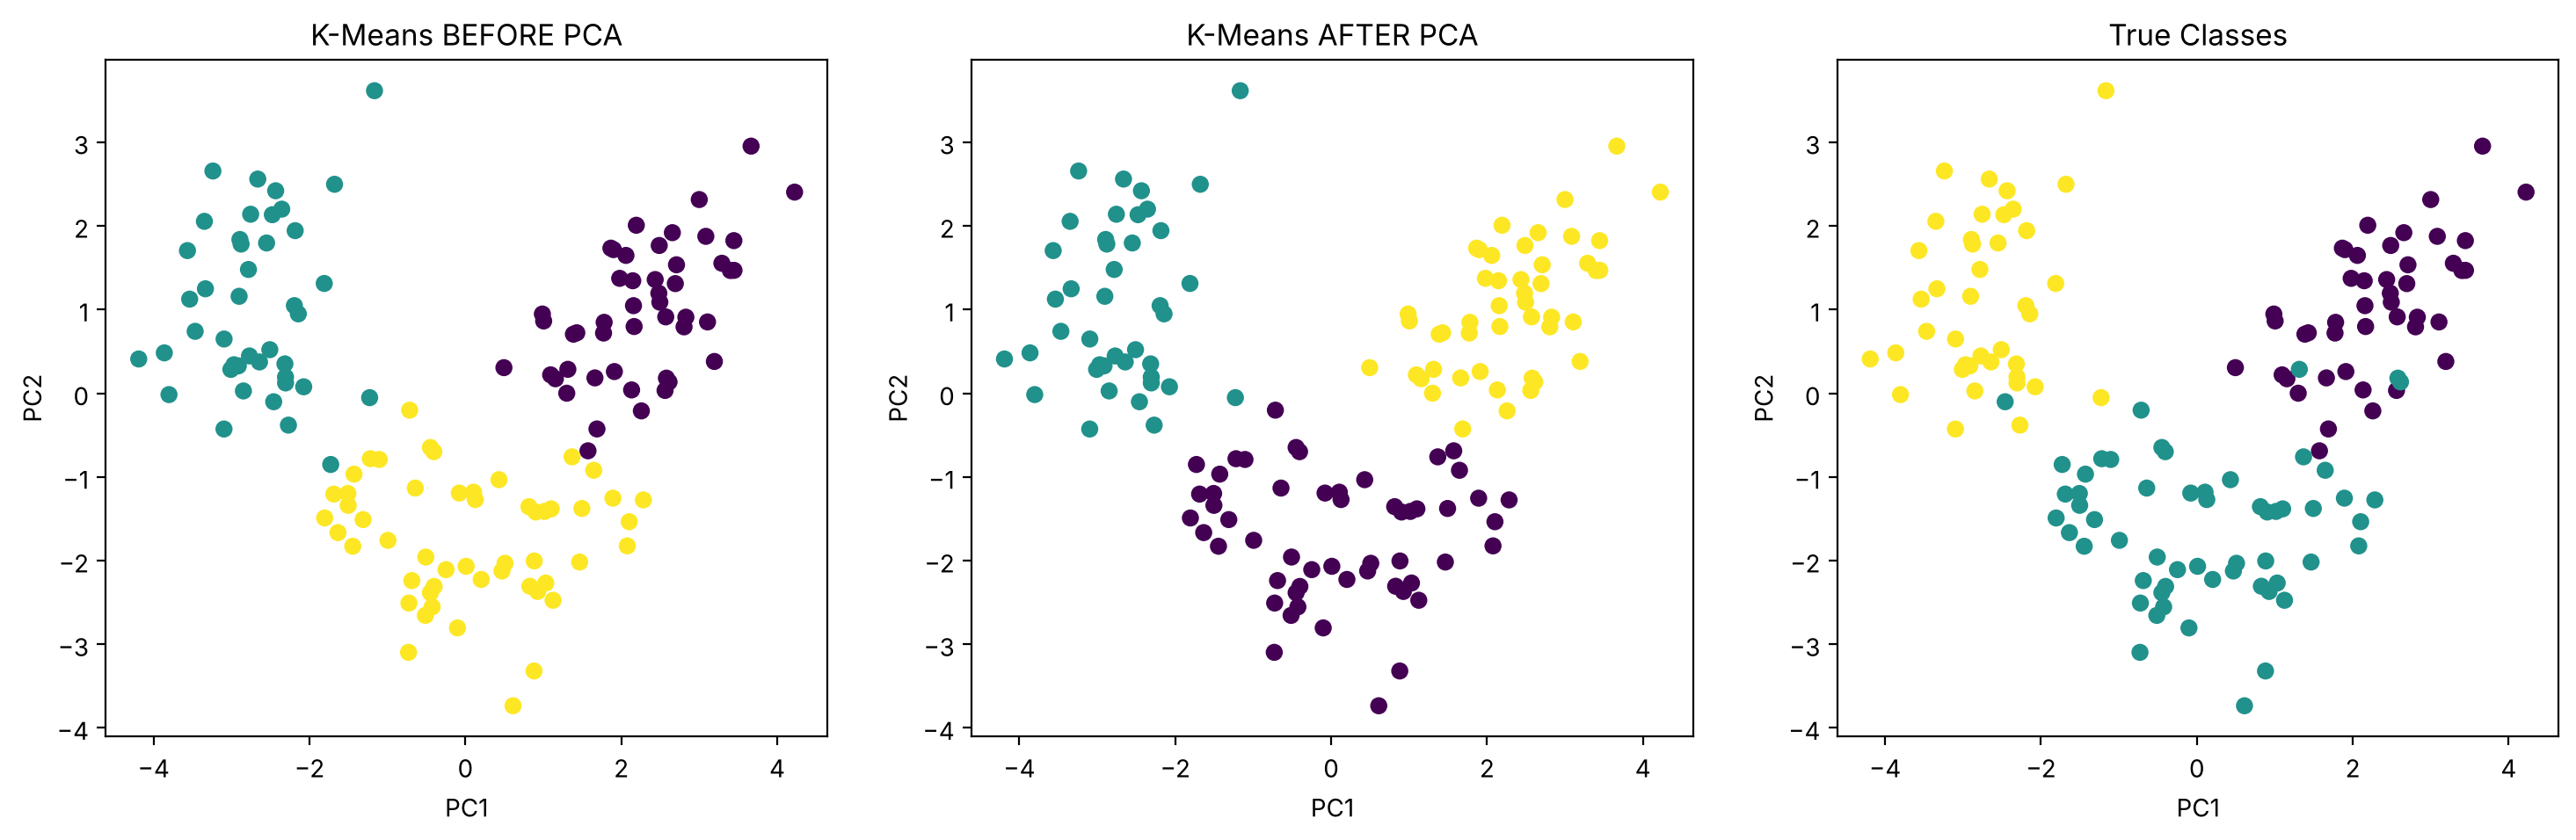

In [10]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_labels_before, cmap='viridis')
plt.title('K-Means BEFORE PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 3, 2)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_labels_after, cmap='viridis')
plt.title('K-Means AFTER PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 3, 3)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='viridis')
plt.title('True Classes')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.show()

### 6. Evaluation on the Test Set
We use the trained models to cluster the test set and calculate the silhouette score.

In [11]:
# Predict on Test Set before PCA
test_labels_before = kmeans_before.predict(X_test_scaled)
test_sil_before = silhouette_score(X_test_scaled, test_labels_before)

# Predict on Test Set after PCA
test_labels_after = kmeans_after.predict(X_test_pca)
test_sil_after = silhouette_score(X_test_pca, test_labels_after)

print("=== Generalization Test Set Metrics ===")
print(f"Test Silhouette Score BEFORE PCA: {test_sil_before:.4f}")
print(f"Test Silhouette Score AFTER PCA:  {test_sil_after:.4f}")

=== Generalization Test Set Metrics ===
Test Silhouette Score BEFORE PCA: 0.3371
Test Silhouette Score AFTER PCA:  0.6083


### 7. Comparing With the True Classes
The silhouette score before PCA is calculated on 13 features and after PCA on only 2 features, so comparing them directly is not completely fair.
Since we have the true labels, we can also use the **Adjusted Rand Index (ARI)**, which shows how close the clusters are to the real classes (1 = perfect match).

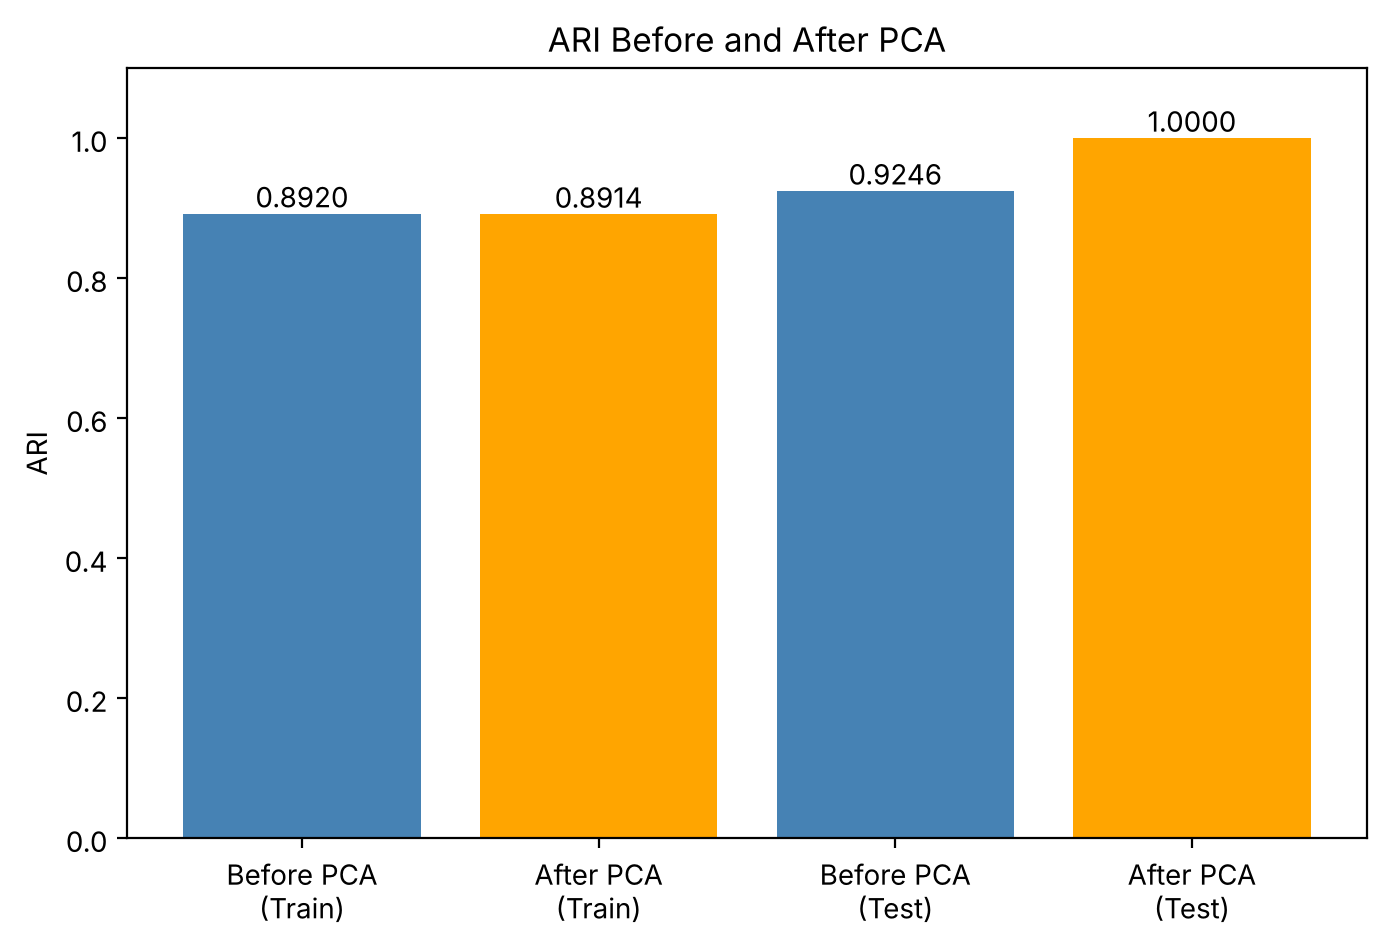

In [12]:
ari_train_before = adjusted_rand_score(y_train, train_labels_before)
ari_train_after = adjusted_rand_score(y_train, train_labels_after)
ari_test_before = adjusted_rand_score(y_test, test_labels_before)
ari_test_after = adjusted_rand_score(y_test, test_labels_after)

names = ['Before PCA\n(Train)', 'After PCA\n(Train)', 'Before PCA\n(Test)', 'After PCA\n(Test)']
values = [ari_train_before, ari_train_after, ari_test_before, ari_test_after]
colors = ['steelblue', 'orange', 'steelblue', 'orange']

plt.figure(figsize=(8, 5))
bars = plt.bar(names, values, color=colors)
plt.bar_label(bars, fmt='%.4f')
plt.ylim(0, 1.1)
plt.ylabel('ARI')
plt.title('ARI Before and After PCA')
plt.show()

### Bonus: Different Number of PCA Components
We try K-Means with different numbers of PCA components and compare the silhouette score and ARI.

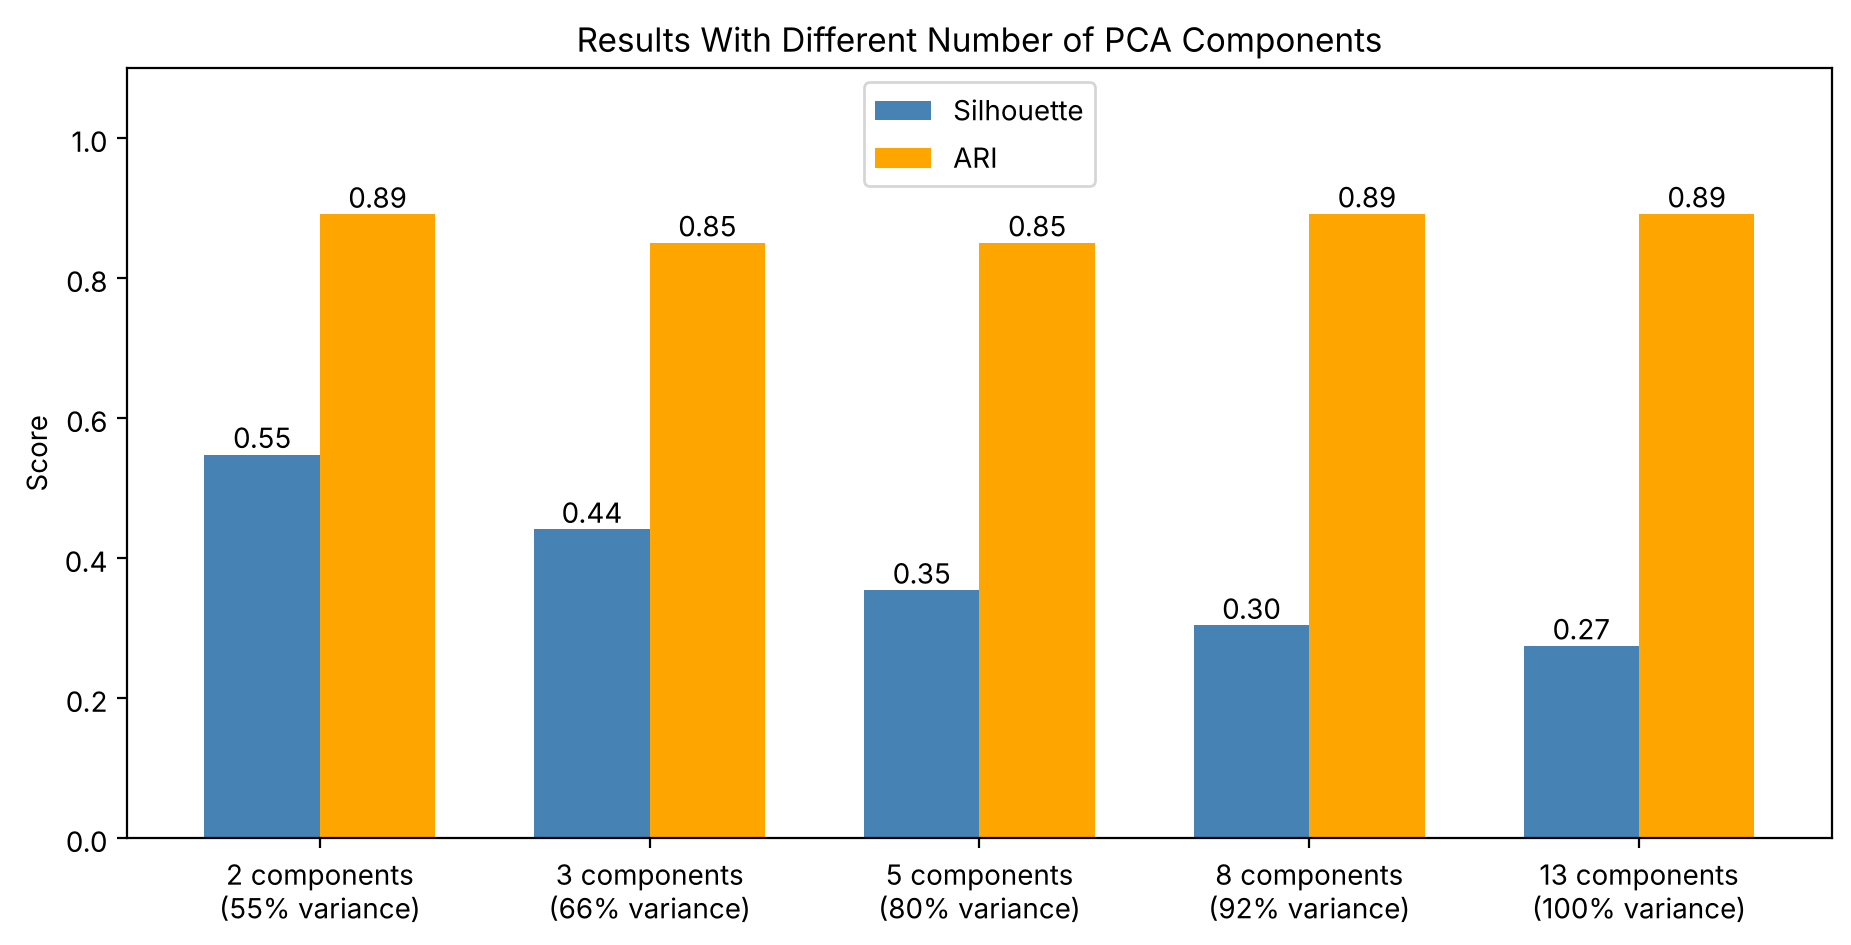

In [13]:
components = [2, 3, 5, 8, 13]
variance_list = []
silhouette_list = []
ari_list = []

for n in components:
    pca_n = PCA(n_components=n, random_state=42)
    X_n = pca_n.fit_transform(X_train_scaled)
    labels_n = KMeans(n_clusters=3, random_state=42).fit_predict(X_n)

    variance_list.append(pca_n.explained_variance_ratio_.sum())
    silhouette_list.append(silhouette_score(X_n, labels_n))
    ari_list.append(adjusted_rand_score(y_train, labels_n))

x = np.arange(len(components))
width = 0.35

plt.figure(figsize=(11, 5))
bars1 = plt.bar(x - width/2, silhouette_list, width, label='Silhouette', color='steelblue')
bars2 = plt.bar(x + width/2, ari_list, width, label='ARI', color='orange')

plt.bar_label(bars1, fmt='%.2f')
plt.bar_label(bars2, fmt='%.2f')

# Show the variance kept under each group
labels = [f'{n} components\n({v:.0%} variance)' for n, v in zip(components, variance_list)]
plt.xticks(x, labels)
plt.ylim(0, 1.1)
plt.ylabel('Score')
plt.title('Results With Different Number of PCA Components')
plt.legend()
plt.show()

When we add more components, the silhouette score goes down, but the ARI stays around the same. So 2 components are enough for this dataset.

### Bonus: DBSCAN Before and After PCA

We apply DBSCAN on the scaled data (13 features) and on the PCA components (2 features), the same way we did with K-Means.
DBSCAN needs an `eps` value. Distances are bigger in 13 dimensions, so we used a bigger `eps` before PCA (we tried a few values and kept the best).
DBSCAN gives the label -1 to noise points (points that don't belong to any cluster).

In [14]:
dbscan_before = DBSCAN(eps=2.2, min_samples=5)
db_labels_before = dbscan_before.fit_predict(X_train_scaled)

dbscan_after = DBSCAN(eps=0.7, min_samples=5)
db_labels_after = dbscan_after.fit_predict(X_train_pca)

print("Noise points before PCA:", list(db_labels_before).count(-1))
print("Noise points after PCA: ", list(db_labels_after).count(-1))
print("ARI before PCA:", round(adjusted_rand_score(y_train, db_labels_before), 4))
print("ARI after PCA: ", round(adjusted_rand_score(y_train, db_labels_after), 4))

Noise points before PCA: 46
Noise points after PCA:  9
ARI before PCA: 0.3491
ARI after PCA:  0.4508


Noise points (-1) appear in purple.

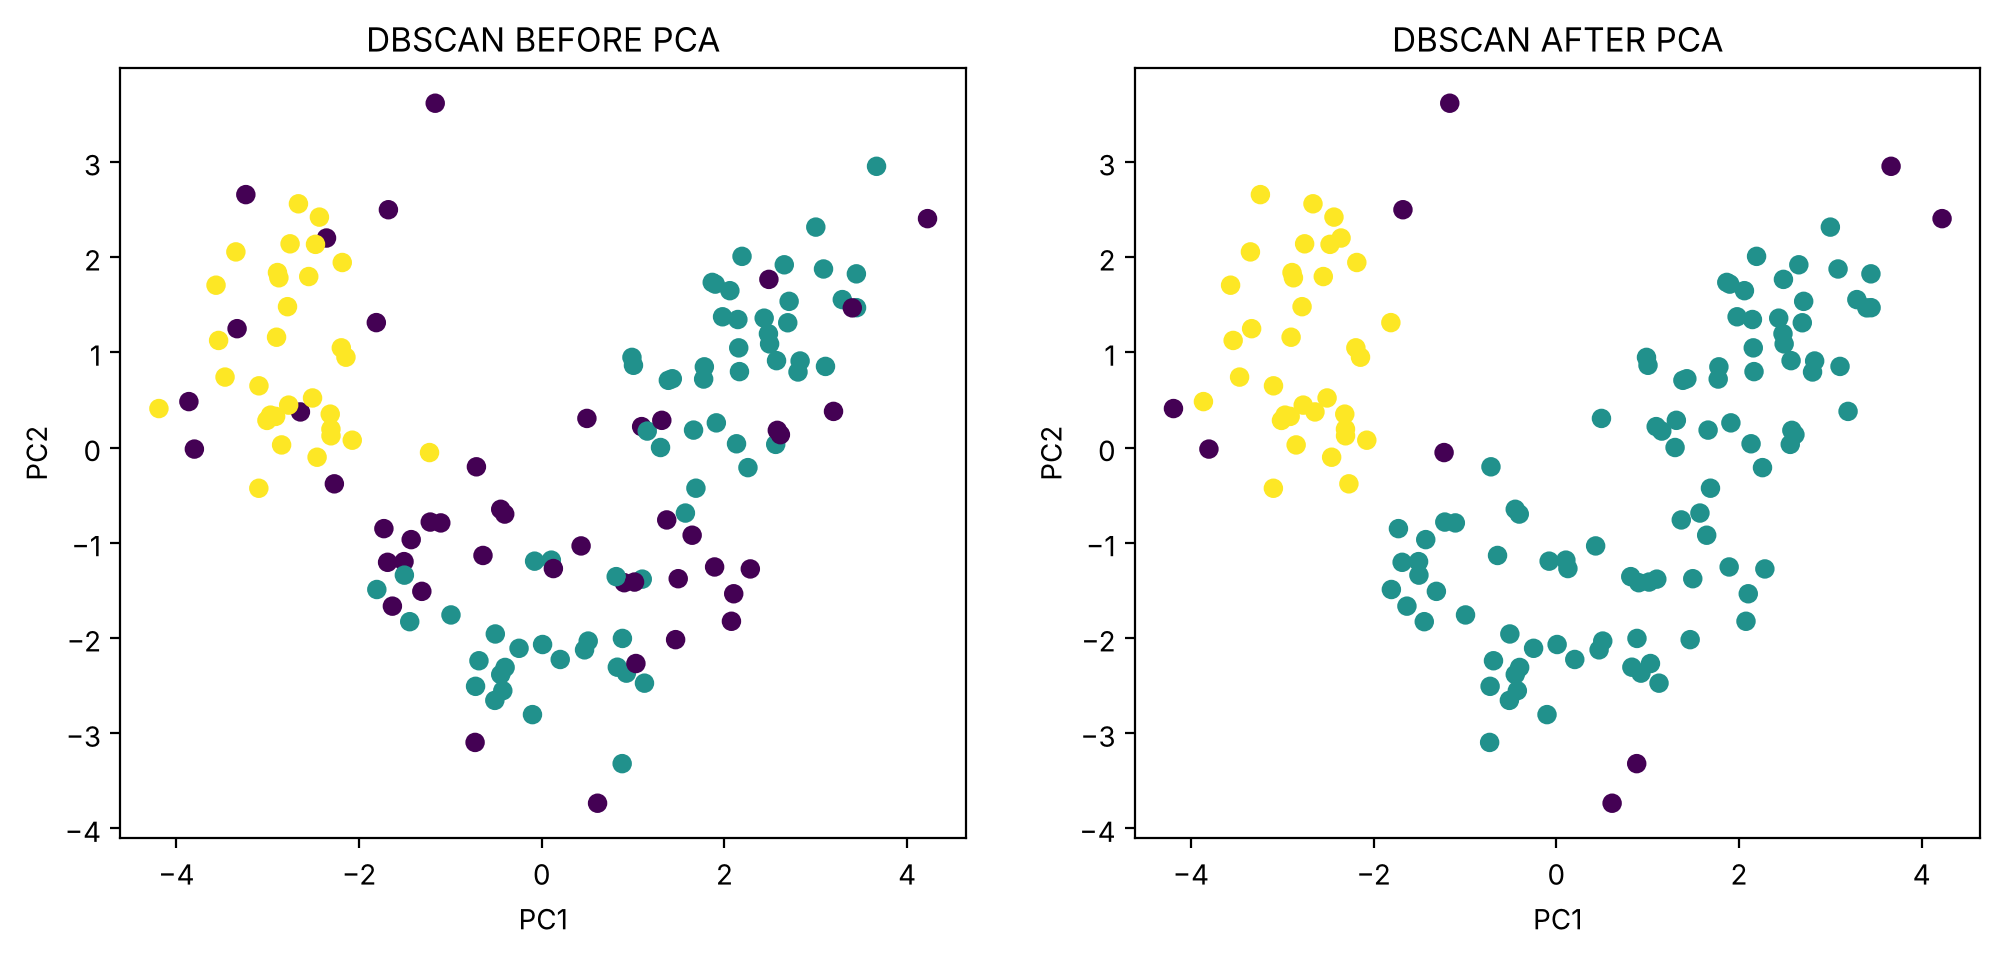

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=db_labels_before, cmap='viridis')
plt.title('DBSCAN BEFORE PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 2, 2)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=db_labels_after, cmap='viridis')
plt.title('DBSCAN AFTER PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.show()

**K-Means vs DBSCAN**

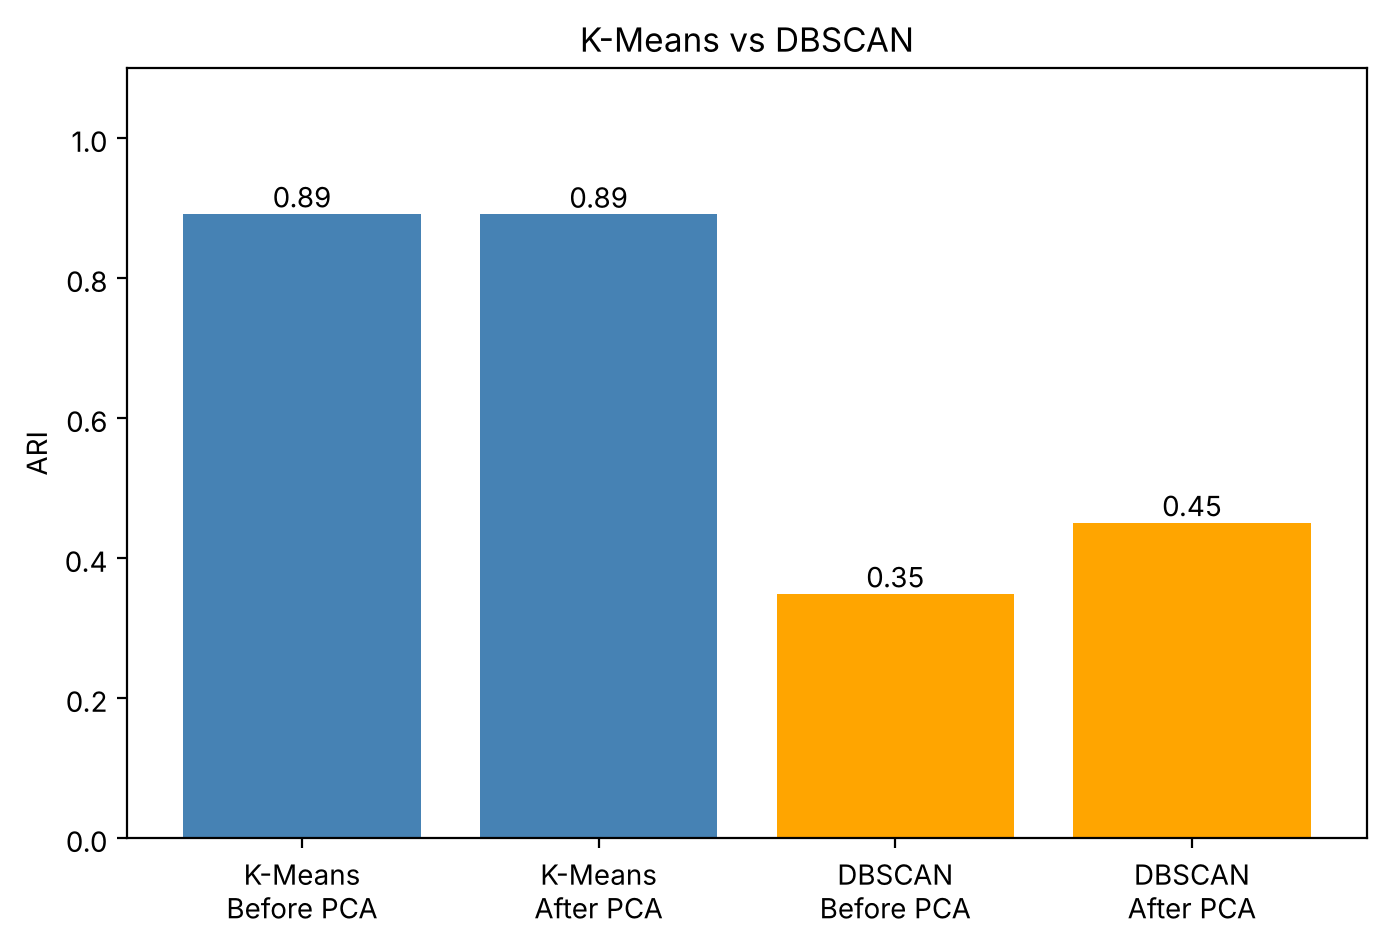

In [16]:
names = ['K-Means\nBefore PCA', 'K-Means\nAfter PCA', 'DBSCAN\nBefore PCA', 'DBSCAN\nAfter PCA']
values = [ari_train_before, ari_train_after,
          adjusted_rand_score(y_train, db_labels_before), adjusted_rand_score(y_train, db_labels_after)]
colors = ['steelblue', 'steelblue', 'orange', 'orange']

plt.figure(figsize=(8, 5))
bars = plt.bar(names, values, color=colors)
plt.bar_label(bars, fmt='%.2f')
plt.ylim(0, 1.1)
plt.ylabel('ARI')
plt.title('K-Means vs DBSCAN')
plt.show()

* **Before PCA**, DBSCAN found only 2 clusters and marked 46 points as noise, because in 13 dimensions the points are spread out and it is hard to find dense areas.
* **After PCA**, it worked better: noise dropped to 9 points and the ARI went up from 0.35 to 0.45. So PCA helped DBSCAN more than it helped K-Means.
* But in both cases DBSCAN merged two of the wine classes into one cluster, because these classes are close to each other with no empty space between them.
* K-Means is much better on this dataset (ARI about 0.89), because the wine classes are compact round groups, which is what K-Means expects.

### 8. Analysis

**How did PCA affect clustering results?**
The silhouette score went up a lot after PCA (0.27 to 0.55 on train, 0.34 to 0.61 on test). But the ARI stayed almost the same on the training set (0.892 vs 0.891),
which means the clusters themselves did not really change. Most of the higher silhouette comes from having fewer dimensions, not from better clusters.

**Did visualization become clearer?**
Yes. We can't plot 13 features, but with 2 components we can clearly see 3 groups, and they look very similar to the true classes.

**Did you lose important information?**
The 2 components kept about 55% of the variance, so we lost about 45% of the information. But this didn't hurt the clustering, because the ARI stayed almost the same.
We also lose the meaning of the original features, because each component is a mix of all 13 features.

**Which approach is better and why?**
K-Means after PCA is better for this dataset. It gives almost the same results with only 2 features instead of 13, and it is easier to visualize and understand.

### 9. Key Insights
* Scaling is important because the features have very different ranges.
* PCA with 2 components kept about 55% of the variance.
* The silhouette score doubled after PCA, but the ARI stayed almost the same, so the clusters didn't really change.
* We should be careful when comparing silhouette scores calculated on different numbers of features.
* PCA made the results much easier to visualize.
* For the Wine dataset, using PCA before K-Means is a good choice.
* K-Means worked much better than DBSCAN on this dataset, before and after PCA.